In [3]:
"""Step 2: UCCSD-VQE for H2, first at 0.74 Angstrom, then along the dissociation curve."""
import csv
import time
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pennylane as qml
from pennylane import numpy as pnp

from vqe_common import (
    CHEMICAL_ACCURACY_HA,
    build_hamiltonian,
    exact_energy,
    h2_geometry,
    hf_energy,
    minimise_energy,
)

# __file__ is undefined in Jupyter; there the working directory is code/ (needed for the vqe_common import).
try:
    ROOT = Path(__file__).resolve().parent.parent
except NameError:
    ROOT = Path.cwd().resolve().parent
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

STEP_SIZE = 0.05
MAX_STEPS = 300
CONV_TOL = 1e-6
# Consecutive steps below CONV_TOL needed to stop. 1 reproduces the 2026-10-08 run.
PATIENCE = 5


def run_uccsd(hamiltonian, n_qubits, n_electrons):
    """Minimise <H> over UCCSD parameters, starting from the HF state (all parameters 0)."""
    singles, doubles = qml.qchem.excitations(n_electrons, n_qubits)
    s_wires, d_wires = qml.qchem.excitations_to_wires(singles, doubles)
    hf_state = qml.qchem.hf_state(n_electrons, n_qubits)
    dev = qml.device("lightning.qubit", wires=n_qubits)

    @qml.qnode(dev, diff_method="adjoint")
    def energy(weights):
        qml.UCCSD(weights, wires=range(n_qubits), s_wires=s_wires, d_wires=d_wires, init_state=hf_state)
        return qml.expval(hamiltonian)

    weights = pnp.zeros(len(singles) + len(doubles), requires_grad=True)
    history, weights = minimise_energy(energy, weights, STEP_SIZE, MAX_STEPS, CONV_TOL, PATIENCE)
    return history, len(weights)


def main():
    RESULTS.mkdir(exist_ok=True)
    FIGURES.mkdir(exist_ok=True)

    # Part 1: one geometry, with the optimisation trace.
    symbols, coordinates = h2_geometry(0.74)
    hamiltonian, n_qubits, n_electrons = build_hamiltonian(symbols, coordinates)
    e_exact = exact_energy(hamiltonian, n_qubits, n_electrons)
    history, n_params = run_uccsd(hamiltonian, n_qubits, n_electrons)
    print("H2 at 0.74 Angstrom")
    print(f"  parameters        : {n_params}")
    print(f"  optimiser steps   : {len(history) - 1}")
    print(f"  start energy (HF) : {history[0]:.6f} Ha")
    print(f"  final VQE energy  : {history[-1]:.6f} Ha")
    print(f"  exact energy      : {e_exact:.6f} Ha")
    print(f"  error             : {(history[-1] - e_exact) * 1000:.4f} mHa")

    plt.figure(figsize=(5, 3.5))
    plt.semilogy(np.abs(np.array(history) - e_exact) * 1000 + 1e-9, label="UCCSD-VQE")
    plt.axhline(CHEMICAL_ACCURACY_HA * 1000, color="gray", linestyle="--", label="1.6 mHa")
    plt.xlabel("Optimiser step")
    plt.ylabel("Error vs exact (mHa)")
    plt.title("H2, STO-3G, 0.74 Angstrom")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURES / "h2_convergence.png", dpi=150)
    plt.close()

    # Part 2: dissociation curve.
    bond_lengths = np.round(np.linspace(0.4, 2.5, 22), 2)
    rows = []
    print("\n  R (A)    E_HF        E_exact     E_VQE       error (mHa)  steps")
    for r in bond_lengths:
        symbols, coordinates = h2_geometry(float(r))
        hamiltonian, n_qubits, n_electrons = build_hamiltonian(symbols, coordinates)
        e_hf = hf_energy(hamiltonian, n_qubits, n_electrons)
        e_exact = exact_energy(hamiltonian, n_qubits, n_electrons)
        start = time.perf_counter()
        history, n_params = run_uccsd(hamiltonian, n_qubits, n_electrons)
        elapsed = time.perf_counter() - start
        error_mha = (history[-1] - e_exact) * 1000
        print(f"  {r:5.2f}  {e_hf:+.6f}  {e_exact:+.6f}  {history[-1]:+.6f}  {error_mha:10.4f}  {len(history) - 1:5d}")
        rows.append(["H2", r, "UCCSD", n_params, len(history) - 1, e_hf, e_exact, history[-1], error_mha, elapsed])

    with open(RESULTS / "h2_dissociation.csv", "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["molecule", "bond_length_A", "ansatz", "n_params", "steps", "e_hf", "e_exact", "e_vqe", "error_mHa", "seconds"])
        writer.writerows(rows)

    data = np.array([[row[1], row[5], row[6], row[7]] for row in rows], dtype=float)
    plt.figure(figsize=(5, 3.5))
    plt.plot(data[:, 0], data[:, 1], label="Hartree-Fock")
    plt.plot(data[:, 0], data[:, 2], label="Exact (FCI)")
    plt.plot(data[:, 0], data[:, 3], "o", markersize=3, label="UCCSD-VQE")
    plt.xlabel("H-H bond length (Angstrom)")
    plt.ylabel("Energy (Ha)")
    plt.title("H2 dissociation curve, STO-3G")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURES / "h2_dissociation.png", dpi=150)
    plt.close()

    errors = np.array([row[8] for row in rows])
    n_ok = int(np.sum(np.abs(errors) < CHEMICAL_ACCURACY_HA * 1000))
    print(f"\nGeometries within chemical accuracy: {n_ok} of {len(rows)}")
    print(f"Largest error: {np.max(np.abs(errors)):.4f} mHa")


if __name__ == "__main__":
    main()


H2 at 0.74 Angstrom
  parameters        : 3
  optimiser steps   : 83
  start energy (HF) : -1.116759 Ha
  final VQE energy  : -1.137281 Ha
  exact energy      : -1.137284 Ha
  error             : 0.0026 mHa

  R (A)    E_HF        E_exact     E_VQE       error (mHa)  steps
   0.40  -0.904361  -0.914150  -0.914149      0.0002     84
   0.50  -1.042996  -1.055160  -1.055160      0.0000     84
   0.60  -1.101128  -1.116286  -1.116284      0.0024     81
   0.70  -1.117349  -1.136189  -1.136188      0.0014     87
   0.80  -1.110850  -1.134148  -1.134146      0.0019     86
   0.90  -1.091914  -1.120560  -1.120557      0.0029     84
   1.00  -1.066109  -1.101150  -1.101149      0.0011     90
   1.10  -1.036539  -1.079193  -1.079190      0.0029     87
   1.20  -1.005107  -1.056741  -1.056740      0.0010     93
   1.30  -0.973111  -1.035186  -1.035183      0.0035     92
   1.40  -0.941481  -1.015468  -1.015467      0.0011     93
   1.50  -0.910874  -0.998149  -0.998149      0.0003     99
   1.6

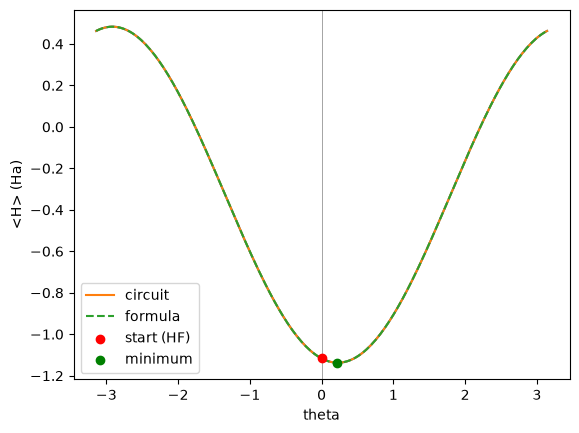

In [5]:
%matplotlib inline
plt.plot(thetas, E, label="circuit")
plt.plot(thetas, fit, "--", label="formula")
plt.axvline(0, color="gray", lw=0.5)
plt.scatter([0], [E[100]], color="red", zorder=3, label="start (HF)")
plt.scatter([thetas[E.argmin()]], [E.min()], color="green", zorder=3, label="minimum")
plt.xlabel("theta"); plt.ylabel("<H> (Ha)"); plt.legend(); plt.show()

max |E - fit|: 9.807325413446755e-07
E(0): -1.1167593103409303  E(pi): 0.46261825871610984


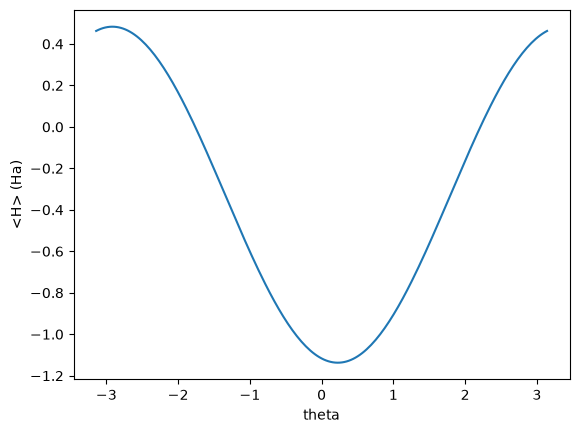

In [6]:
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt
from vqe_common import build_hamiltonian, h2_geometry

H, n_qubits, n_electrons = build_hamiltonian(*h2_geometry(0.74))
dev = qml.device("lightning.qubit", wires=n_qubits)

@qml.qnode(dev)
def energy(theta):
    qml.BasisState(np.array([1, 1, 0, 0]), wires=range(4))   # 起始态 |1100>
    qml.DoubleExcitation(theta, wires=[0, 1, 2, 3])          # 唯一的一个参数
    return qml.expval(H)                                     # 输出，也就是 loss

thetas = np.linspace(-np.pi, np.pi, 201)
E = np.array([energy(t) for t in thetas])
fit = -0.327071 - 0.789689 * np.cos(thetas) - 0.181210 * np.sin(thetas)

print("max |E - fit|:", np.abs(E - fit).max())
print("E(0):", float(energy(0.0)), " E(pi):", float(energy(np.pi)))
plt.plot(thetas, E); plt.xlabel("theta"); plt.ylabel("<H> (Ha)"); plt.show()